<a href="https://colab.research.google.com/github/ElisabettaPellegrini/NLP-POS-Tagging-Italian/blob/main/NLP_POS_Tagging_Linguistica_Computazionale_Elisabetta_Pellegrini.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# Importo la libreria SpaCy, uno standard industriale per l'elaborazione del linguaggio naturale (NLP)
import spacy

# Scarico il modello pre-addestrato per la lingua italiana (dimensione media)
! python -m spacy download it_core_news_md

# Importo il modello linguistico appena scaricato
import it_core_news_md

# Importo pandas, libreria fondamentale per la manipolazione e l'analisi dei dati (dataframe ed esportazione Excel)
import pandas as pd

# Carico in memoria il modello italiano di SpaCy, che contiene vocabolario, regole sintattiche e pesi per il NLP
nlp = spacy.load('it_core_news_md')

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 42.4/42.4 MB 12.2 MB/s eta 0:00:00
✔ Download and installation successful
You can now load the package via spacy.load('it_core_news_md')
⚠ Restart to reload dependencies
If you are in a Jupyter or Colab notebook, you may need to restart Python in
order to load all the package's dependencies. You can do this by selecting the
'Restart kernel' or 'Restart runtime' option.


In [2]:
# Definisco il primo testo da analizzare: un testo dal linguaggio formale, giornalistico/accademico
testo1 = "In un'epoca caratterizzata da un rapido sviluppo tecnologico e una crescente consapevolezza dell'importanza dell'inclusività, l'uso dell'intelligenza artificiale (IA) nelle tecnologie assistive per l'accessibilità delle applicazioni web e mobile rappresenta un punto di svolta fondamentale. Questa prefazione si propone di introdurre il lettore al tema affascinante e cruciale dell'integrazione dell'IA nel campo delle tecnologie assistive, esplorando il suo impatto, le sfide e le prospettive future."

# Faccio processare il testo dal modello NLP di SpaCy. L'oggetto 'doc' conterrà ora il testo con tutte le annotazioni linguistiche automatiche (POS, lemmi, sintassi)
doc = nlp(testo1)

# Stampo a schermo il documento processato (apparirà come testo normale, ma sotto il cofano è ricco di dati)
print(doc)

# Itero su ogni singola parola (token) del documento processato
for token in doc:
  # Stampo solo il testo grezzo di ogni token (ad es. per verificare che la punteggiatura sia divisa correttamente)
  print(token.text)

# Stampo il numero totale di token presenti in questo primo testo
len (doc)

# Itero nuovamente su ogni token
for token in doc:
  # Stampo la parola (token.text) e accanto la sua Part-Of-Speech (POS) calcolata dal modello (token.pos_)
  print(token.text, token.pos_)

# Inizializzo una lista vuota che conterrà i dati formattati per essere esportati in Excel
dati_per_excel = []

# Itero sui token per preparare i dati del Gold Standard
for token in doc:
  # Ignoro i token che sono solo spazi vuoti, per avere un dataset pulito
  if not token.is_space:
    # Aggiungo un dizionario alla lista per ogni parola. Prevedo colonne vuote per l'annotazione umana e una per l'output del sistema
    dati_per_excel.append({
        "TOKEN": token.text,
        "MANUAL ANNOTATION1": "",
        "MANUAL ANNOTATION2": "",
        "SYSTEM OUT": token.pos_
    })

# Converto la lista di dizionari in un DataFrame pandas, una struttura tabellare simile a un foglio di calcolo
df = pd.DataFrame(dati_per_excel)

# Definisco il nome del file Excel di output che servirà come template vuoto per l'annotazione manuale
file_excel_LinguisticaComputazionale_Empty = "Annotazione_POS_Tagging_Empty.xlsx"

# Esporto il DataFrame in un file Excel, omettendo l'indice di riga di pandas (index=False)
df.to_excel(file_excel_LinguisticaComputazionale_Empty, index=False)

# Stampo a schermo il nome del file salvato per conferma
print(file_excel_LinguisticaComputazionale_Empty)

In un'epoca caratterizzata da un rapido sviluppo tecnologico e una crescente consapevolezza dell'importanza dell'inclusività, l'uso dell'intelligenza artificiale (IA) nelle tecnologie assistive per l'accessibilità delle applicazioni web e mobile rappresenta un punto di svolta fondamentale. Questa prefazione si propone di introdurre il lettore al tema affascinante e cruciale dell'integrazione dell'IA nel campo delle tecnologie assistive, esplorando il suo impatto, le sfide e le prospettive future.
In
un'
epoca
caratterizzata
da
un
rapido
sviluppo
tecnologico
e
una
crescente
consapevolezza
dell'
importanza
dell'
inclusività
,
l'
uso
dell'
intelligenza
artificiale
(
IA
)
nelle
tecnologie
assistive
per
l'
accessibilità
delle
applicazioni
web
e
mobile
rappresenta
un
punto
di
svolta
fondamentale
.
Questa
prefazione
si
propone
di
introdurre
il
lettore
al
tema
affascinante
e
cruciale
dell'
integrazione
dell'
IA
nel
campo
delle
tecnologie
assistive
,
esplorando
il
suo
impatto
,
le
sfide
e
le
pr

In [3]:
# Definisco il secondo testo: un testo dal linguaggio informale (studentesco), con abbreviazioni ("xkè", "nn") ed errori per testare la robustezza del modello
testo2= "Il problema dell’esame è Giannetti che l'anno scorso bocciò tantissime persone xkè si fissa con la parte matematica , chiede sempre la definizione di gradiente , divergenza e altre cose sempre di matematica sulle quali luchini e pralits nn insistevano mai sapendo ke nn siamo ferratissimi ( nn avendo fatto nemmeno mate )."

# Processo il secondo testo con il modello NLP
doc2 = nlp(testo2)

# Stampo il secondo documento
print(doc2)

# Itero e stampo il testo grezzo di ogni token del secondo testo
for token in doc2:
  print(token.text)

# Stampo il numero totale di token del secondo testo
len(doc2)

# Itero e stampo la parola e il tag POS per il secondo testo
for token in doc2:
  print(token.text, token.pos_)

# Inizializzo la lista per il secondo file Excel
dati_per_excel2 = []

# Preparo i dati del secondo testo ignorando gli spazi
for token in doc2:
  if not token.is_space:
    dati_per_excel2.append({
        "TOKEN": token.text,
        "MANUAL ANNOTATION1": "",
        "MANUAL ANNOTATION2": "",
        "SYSTEM OUT": token.pos_
    })

# Converto in DataFrame i dati del secondo testo
df = pd.DataFrame(dati_per_excel2)

# Definisco il nome del secondo file Excel
file_excel2_LinguisticaComputazionale_Empty = "Annotazione2_POS_Tagging_Empty.xlsx"

# Esporto il secondo DataFrame in Excel
df.to_excel(file_excel2_LinguisticaComputazionale_Empty, index=False)

Il problema dell’esame è Giannetti che l'anno scorso bocciò tantissime persone xkè si fissa con la parte matematica , chiede sempre la definizione di gradiente , divergenza e altre cose sempre di matematica sulle quali luchini e pralits nn insistevano mai sapendo ke nn siamo ferratissimi ( nn avendo fatto nemmeno mate ).
Il
problema
dell’
esame
è
Giannetti
che
l'
anno
scorso
bocciò
tantissime
persone
xkè
si
fissa
con
la
parte
matematica
,
chiede
sempre
la
definizione
di
gradiente
,
divergenza
e
altre
cose
sempre
di
matematica
sulle
quali
luchini
e
pralits
nn
insistevano
mai
sapendo
ke
nn
siamo
ferratissimi
(
nn
avendo
fatto
nemmeno
mate
)
.
Il DET
problema NOUN
dell’ ADP
esame NOUN
è AUX
Giannetti PROPN
che SCONJ
l' DET
anno NOUN
scorso ADJ
bocciò VERB
tantissime DET
persone NOUN
xkè PROPN
si PRON
fissa VERB
con ADP
la DET
parte NOUN
matematica ADJ
, PUNCT
chiede VERB
sempre ADV
la DET
definizione NOUN
di ADP
gradiente NOUN
, PUNCT
divergenza NOUN
e CCONJ
altre ADJ
cose NOUN
sempre ADV

Mounted at /content/drive
['ADP', 'DET', 'NOUN', 'VERB', 'ADP', 'DET', 'ADJ', 'NOUN', 'ADJ', 'CCONJ', 'DET', 'ADJ', 'NOUN', 'ADP', 'NOUN', 'ADP', 'NOUN', 'PUNCT', 'DET', 'NOUN', 'ADP', 'NOUN', 'ADJ', 'PUNCT', 'NOUN', 'PUNCT', 'ADP', 'NOUN', 'ADJ', 'ADP', 'DET', 'NOUN', 'ADP', 'NOUN', 'NOUN', 'CCONJ', 'ADJ', 'VERB', 'DET', 'NOUN', 'ADP', 'NOUN', 'ADJ', 'PUNCT', 'DET', 'NOUN', 'PRON', 'VERB', 'ADP', 'VERB', 'DET', 'NOUN', 'ADP', 'NOUN', 'ADJ', 'CCONJ', 'ADJ', 'ADP', 'NOUN', 'ADP', 'NOUN', 'ADP', 'NOUN', 'ADP', 'NOUN', 'ADJ', 'PUNCT', 'VERB', 'DET', 'DET', 'NOUN', 'PUNCT', 'DET', 'NOUN', 'CCONJ', 'DET', 'NOUN', 'ADJ', 'PUNCT']
['ADP', 'DET', 'NOUN', 'VERB', 'ADP', 'DET', 'ADJ', 'NOUN', 'ADJ', 'CCONJ', 'DET', 'ADJ', 'NOUN', 'ADP', 'NOUN', 'ADP', 'NOUN', 'PUNCT', 'DET', 'NOUN', 'ADP', 'NOUN', 'ADJ', 'PUNCT', 'PROPN', 'PUNCT', 'ADP', 'NOUN', 'ADJ', 'ADP', 'DET', 'NOUN', 'ADP', 'NOUN', 'NOUN', 'CCONJ', 'ADJ', 'VERB', 'DET', 'NOUN', 'ADP', 'NOUN', 'ADJ', 'PUNCT', 'DET', 'NOUN', 'PRON', 'VERB',

/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


['DET', 'NOUN', 'ADP', 'NOUN', 'AUX', 'PROPN', 'PRON', 'DET', 'NOUN', 'ADJ', 'VERB', 'ADJ', 'NOUN', 'SCONJ', 'PRON', 'VERB', 'ADP', 'DET', 'NOUN', 'ADJ', 'PUNCT', 'VERB', 'ADV', 'DET', 'NOUN', 'ADP', 'NOUN', 'PUNCT', 'NOUN', 'CCONJ', 'ADJ', 'NOUN', 'ADV', 'ADP', 'NOUN', 'ADP', 'PRON', 'PROPN', 'CCONJ', 'PROPN', 'ADV', 'VERB', 'ADV', 'VERB', 'SCONJ', 'ADV', 'AUX', 'ADJ', 'PUNCT', 'ADV', 'AUX', 'VERB', 'ADV', 'NOUN', 'PUNCT', 'PUNCT']
['DET', 'NOUN', 'ADP', 'NOUN', 'AUX', 'PROPN', 'SCONJ', 'DET', 'NOUN', 'ADJ', 'VERB', 'DET', 'NOUN', 'PROPN', 'PRON', 'VERB', 'ADP', 'DET', 'NOUN', 'ADJ', 'PUNCT', 'VERB', 'ADV', 'DET', 'NOUN', 'ADP', 'NOUN', 'PUNCT', 'NOUN', 'CCONJ', 'ADJ', 'NOUN', 'ADV', 'ADP', 'NOUN', 'ADP', 'PRON', 'NOUN', 'CCONJ', 'PROPN', 'NOUN', 'VERB', 'ADV', 'VERB', 'PROPN', 'PRON', 'AUX', 'ADJ', 'PUNCT', 'PRON', 'AUX', 'VERB', 'ADV', 'ADJ', 'PUNCT', 'PUNCT']
['ADJ', 'ADP', 'ADV', 'AUX', 'CCONJ', 'DET', 'NOUN', 'PRON', 'PROPN', 'PUNCT', 'SCONJ', 'VERB']
Classification Report 'TEST


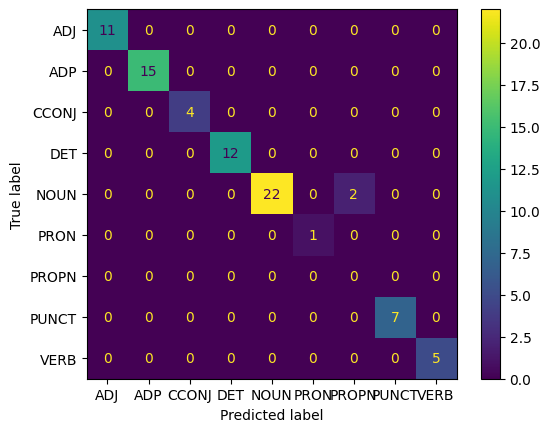

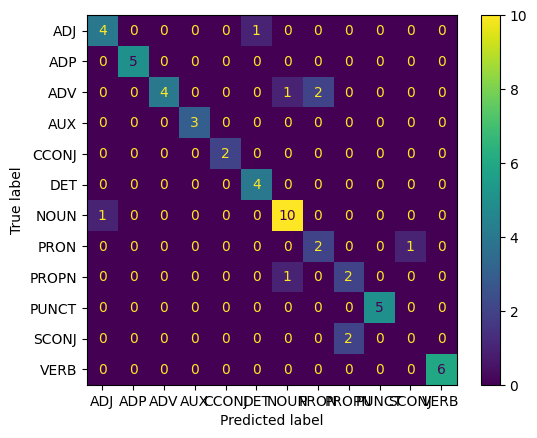

In [4]:
# (Inizio blocco Valutazione) Importo il modulo per connettere Google Colab a Google Drive
from google.colab import drive

# Monto il Google Drive per poter leggere i file Excel che sono stati annotati manualmente e ricaricati
drive.mount('/content/drive')

# Importo pyplot per creare grafici (es. matrici di confusione)
import matplotlib.pyplot as plt

# Importo Counter per contare la frequenza degli elementi
from collections import Counter

# Importo funzioni da scikit-learn per valutare le performance del modello: report di classificazione e matrici di confusione
from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix
from sklearn.metrics import ConfusionMatrixDisplay

# Definisco il percorso del primo file Excel annotato su Google Drive
filename = "/content/drive/MyDrive/Annotazione_POS_Tagging.xlsx"

# Tento di leggere il file come Excel, se fallisce (es. formato errato) provo a leggerlo come CSV
try:
  df = pd.read_excel(filename)
except:
  df = pd.read_csv(filename)

# Estraggo la colonna delle annotazioni manuali umane (il "Gold Standard") e la converto in una lista di stringhe
ground_truth_annotations = df['MANUAL ANNOTATION1'].astype(str).tolist()

# Stampo la lista delle annotazioni manuali
print(ground_truth_annotations)

# Estraggo la colonna delle annotazioni previste dal modello e la converto in lista
predicted_annotations = df['SYSTEM OUT'].astype(str).tolist()

# Stampo la lista delle predizioni del sistema
print(predicted_annotations)

# Creo una lista ordinata di tutte le etichette uniche (es. NOUN, VERB) unendo quelle umane e quelle del sistema
labels= sorted(set(ground_truth_annotations+predicted_annotations))

# Stampo le etichette individuate
print(labels)

# Genero un report di classificazione che calcola Precision, Recall e F1-Score confrontando umano vs macchina. Restituisco i risultati come dizionario (output_dict=True)
CB_test_report = classification_report(ground_truth_annotations, predicted_annotations, labels=labels, target_names=labels, output_dict=True)

# Converto il report in un DataFrame pandas e lo traspongo (scambio righe con colonne) per una visualizzazione migliore
df_CB_test_class_report = pd.DataFrame(CB_test_report).transpose()

# Calcolo la matrice di confusione confrontando etichette vere e predette
CB_test_cfm = confusion_matrix(ground_truth_annotations, predicted_annotations, labels=labels)

# Preparo l'oggetto grafico per visualizzare la matrice di confusione
CB_test_cfm_plot = ConfusionMatrixDisplay(confusion_matrix=CB_test_cfm, display_labels=labels)

# Stampo a schermo il titolo del report
print(f"Classification Report 'TEST")

# Stampo la tabella con Precision, Recall e F1-score
print(f"\n{df_CB_test_class_report}")

# Stampo una linea di separazione
print("="*90)

# Disegno il grafico della matrice di confusione
CB_test_cfm_plot.plot()

# Ripeto l'intero processo di valutazione per il SECONDO TESTO
# Definisco il percorso del secondo file Excel
filename2 = "/content/drive/MyDrive/Annotazione2_POS_Tagging.xlsx"

# Leggo il secondo file Excel o CSV
try:
  df = pd.read_excel(filename2)
except:
  df = pd.read_csv(filename2)

# Estraggo le annotazioni manuali del secondo testo
ground_truth_annotations2 = df['MANUAL ANNOTATION1'].astype(str).tolist()
print(ground_truth_annotations2)

# Estraggo le predizioni del modello per il secondo testo
predicted_annotations2 = df['SYSTEM OUT'].astype(str).tolist()
print(predicted_annotations2)

# Trovo le etichette uniche nel secondo testo
labels= sorted(set(ground_truth_annotations2+predicted_annotations2))
print(labels)

# Genero il report di classificazione per il secondo testo
CB_test_report = classification_report(ground_truth_annotations2, predicted_annotations2,labels=labels, target_names=labels, output_dict=True)
df_CB_test_class_report = pd.DataFrame(CB_test_report).transpose()

# Genero e preparo la matrice di confusione per il secondo testo
CB_test_cfm = confusion_matrix(ground_truth_annotations2, predicted_annotations2, labels=labels)
CB_test_cfm_plot = ConfusionMatrixDisplay(confusion_matrix=CB_test_cfm, display_labels=labels)

# Stampo i risultati di classificazione del secondo testo
print(f"Classification Report 'TEST")
print(f"\n{df_CB_test_class_report}")
print("="*90)

# Visualizzo la matrice di confusione del secondo testo
CB_test_cfm_plot.plot()

['ADP', 'DET', 'NOUN', 'VERB', 'ADP', 'DET', 'ADJ', 'NOUN', 'ADJ', 'CCONJ', 'DET', 'ADJ', 'NOUN', 'ADP', 'NOUN', 'ADP', 'NOUN', 'PUNCT', 'DET', 'NOUN', 'ADP', 'NOUN', 'ADJ', 'PUNCT', 'NOUN', 'PUNCT', 'ADP', 'NOUN', 'ADJ', 'ADP', 'DET', 'NOUN', 'ADP', 'NOUN', 'NOUN', 'CCONJ', 'ADJ', 'VERB', 'DET', 'NOUN', 'ADP', 'NOUN', 'ADJ', 'PUNCT', 'DET', 'NOUN', 'PRON', 'VERB', 'ADP', 'VERB', 'DET', 'NOUN', 'ADP', 'NOUN', 'ADJ', 'CCONJ', 'ADJ', 'ADP', 'NOUN', 'ADP', 'NOUN', 'ADP', 'NOUN', 'ADP', 'NOUN', 'ADJ', 'PUNCT', 'VERB', 'DET', 'DET', 'NOUN', 'PUNCT', 'DET', 'NOUN', 'CCONJ', 'DET', 'NOUN', 'ADJ', 'PUNCT']
['ADP', 'DET', 'NOUN', 'VERB', 'ADP', 'DET', 'ADJ', 'NOUN', 'ADJ', 'CCONJ', 'DET', 'ADJ', 'NOUN', 'ADP', 'NOUN', 'ADP', 'NOUN', 'PUNCT', 'DET', 'NOUN', 'ADP', 'NOUN', 'ADJ', 'PUNCT', 'PROPN', 'PUNCT', 'ADP', 'NOUN', 'ADJ', 'ADP', 'DET', 'NOUN', 'ADP', 'NOUN', 'ADJ', 'CCONJ', 'ADJ', 'VERB', 'DET', 'NOUN', 'ADP', 'NOUN', 'ADJ', 'PUNCT', 'DET', 'NOUN', 'PRON', 'VERB', 'ADP', 'VERB', 'DET', 'NOU

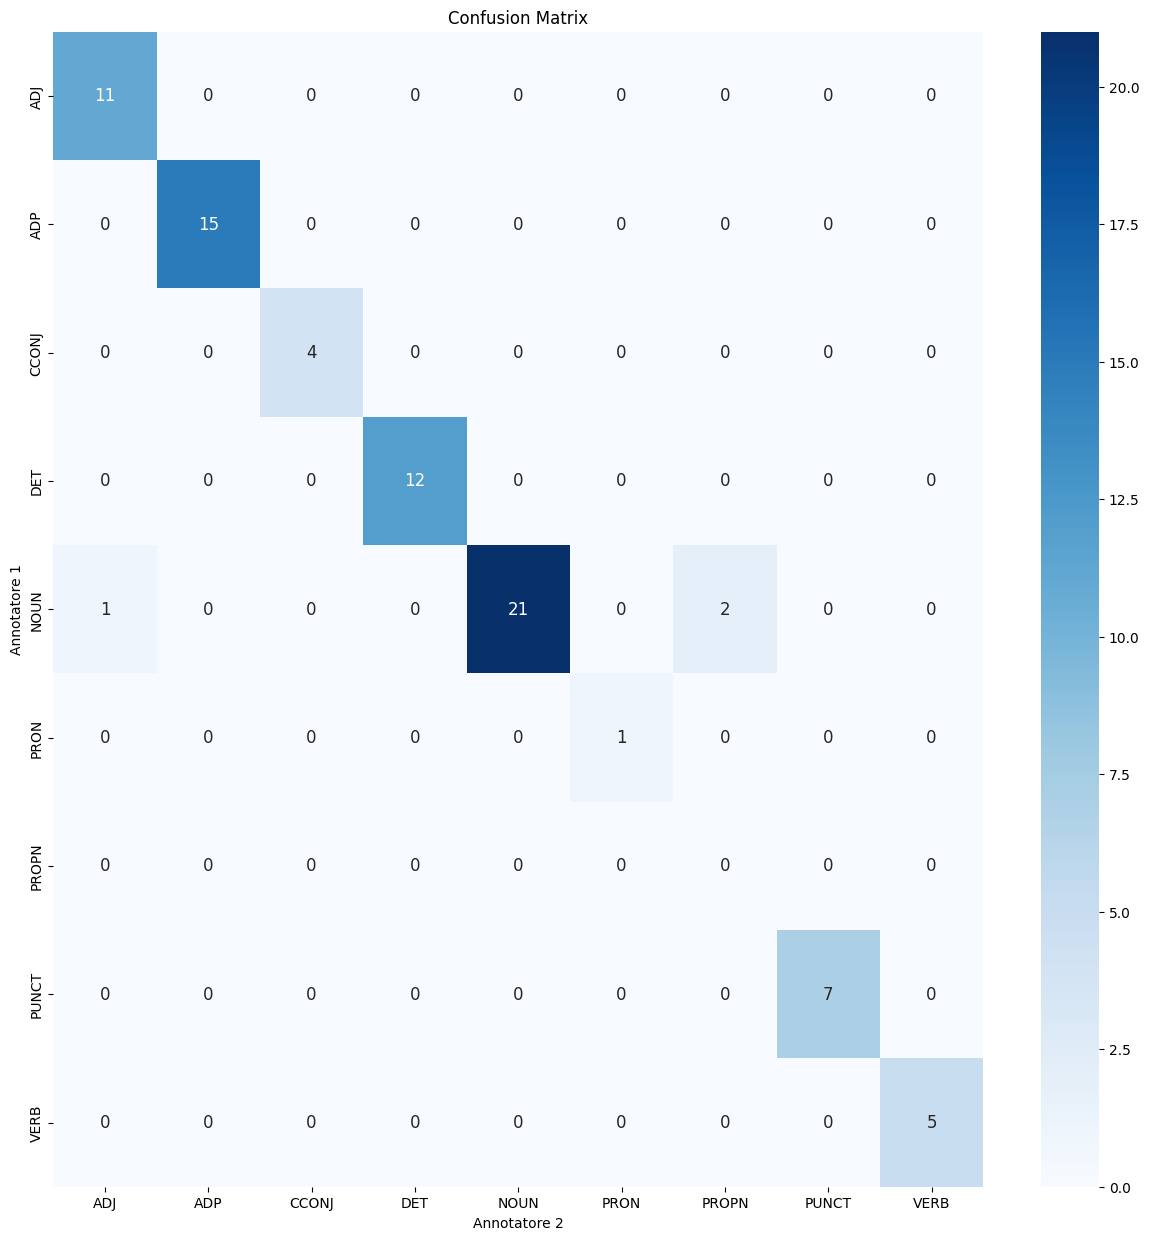

Cohen's kappa 0.953935860058309

Cohen's kappa per class:
 ADJ: 0.9491
 ADP: 1.0000
 CCONJ: 1.0000
 DET: 1.0000
 NOUN: 0.9069
 PRON: 1.0000
 PROPN: 0.0000
 PUNCT: 1.0000
 VERB: 1.0000
['DET', 'NOUN', 'ADP', 'NOUN', 'AUX', 'PROPN', 'PRON', 'DET', 'NOUN', 'ADJ', 'VERB', 'ADJ', 'NOUN', 'SCONJ', 'PRON', 'VERB', 'ADP', 'DET', 'NOUN', 'ADJ', 'PUNCT', 'VERB', 'ADV', 'DET', 'NOUN', 'ADP', 'NOUN', 'PUNCT', 'NOUN', 'CCONJ', 'ADJ', 'NOUN', 'ADV', 'ADP', 'NOUN', 'ADP', 'PRON', 'PROPN', 'CCONJ', 'PROPN', 'ADV', 'VERB', 'ADV', 'VERB', 'SCONJ', 'ADV', 'AUX', 'ADJ', 'PUNCT', 'ADV', 'AUX', 'VERB', 'ADV', 'NOUN', 'PUNCT', 'PUNCT']
['DET', 'NOUN', 'ADP', 'NOUN', 'VERB', 'PROPN', 'PRON', 'DET', 'NOUN', 'ADJ', 'VERB', 'ADJ', 'NOUN', 'SCONJ', 'PRON', 'VERB', 'ADP', 'DET', 'NOUN', 'ADJ', 'PUNCT', 'VERB', 'ADV', 'DET', 'NOUN', 'ADP', 'NOUN', 'PUNCT', 'NOUN', 'CCONJ', 'DET', 'NOUN', 'ADV', 'ADP', 'NOUN', 'ADP', 'PRON', 'PROPN', 'CCONJ', 'PROPN', 'ADV', 'VERB', 'ADV', 'VERB', 'SCONJ', 'ADV', 'AUX', 'ADJ', 'PUNC

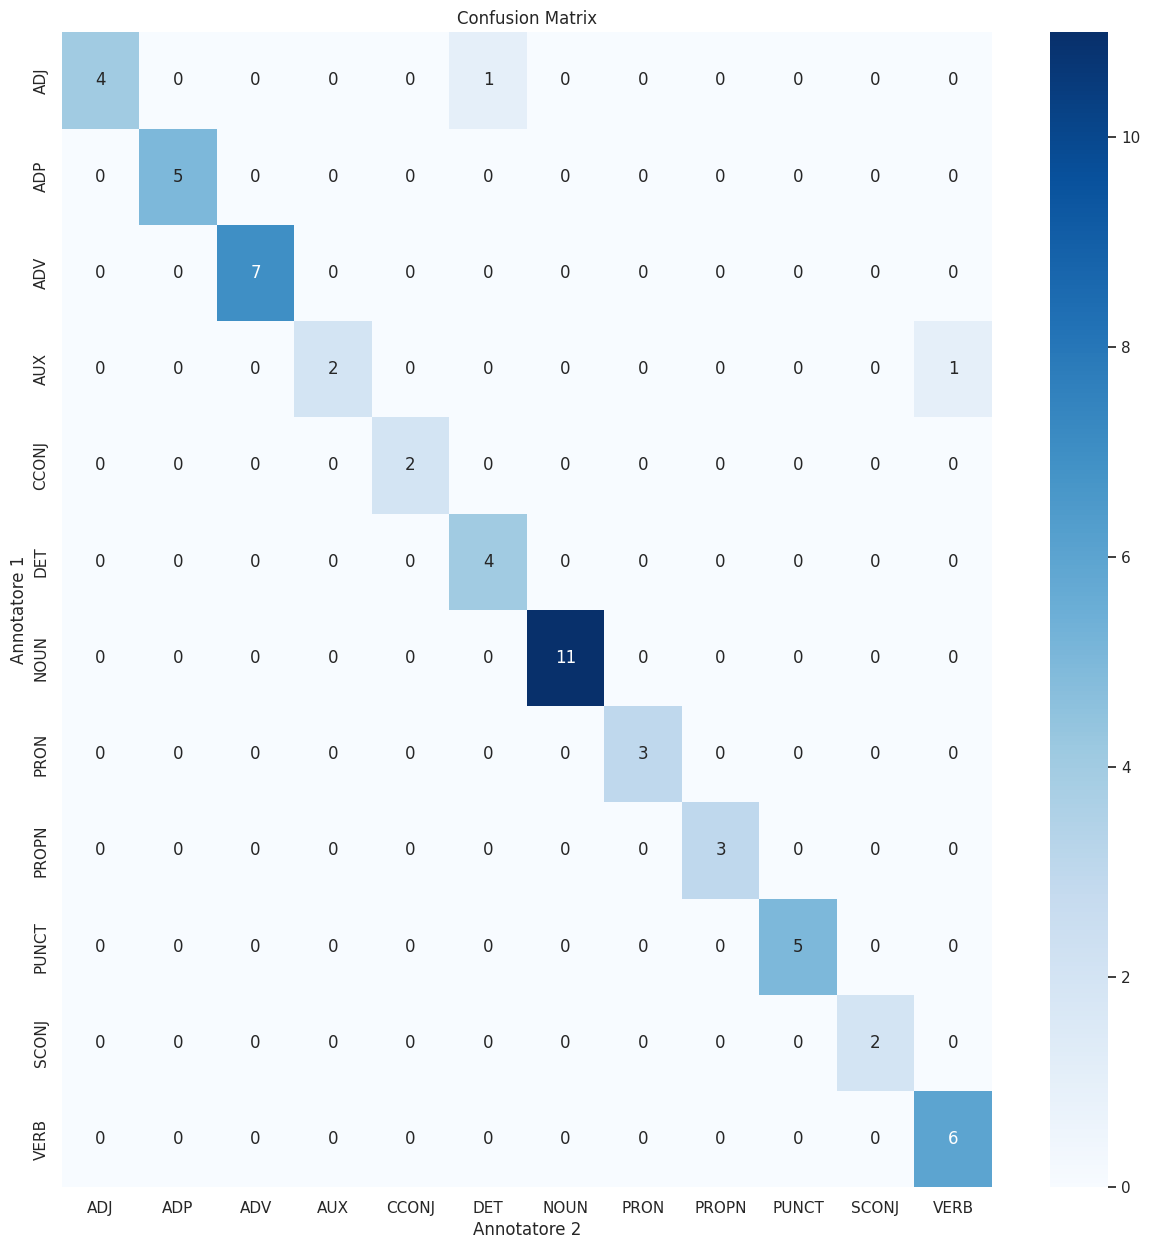

Cohen's kappa 0.960028551034975

Cohen's kappa per class:
 ADJ: 0.8793
 ADP: 1.0000
 ADV: 1.0000
 AUX: 0.7910
 CCONJ: 1.0000
 DET: 0.8793
 NOUN: 1.0000
 PRON: 1.0000
 PROPN: 1.0000
 PUNCT: 1.0000
 SCONJ: 1.0000
 VERB: 0.9130


In [5]:
# (Inizio blocco Inter-Annotator Agreement - IAA)
# Importo moduli per misurare l'accordo tra due diversi esseri umani che annotano lo stesso testo (Cohen's Kappa)
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, cohen_kappa_score
import matplotlib.pyplot as plt

# Importo seaborn per grafici statistici più accattivanti
import seaborn as sn
import pandas as pd

# Carico il primo file annotato per calcolare l'accordo tra annotatore 1 e annotatore 2
percorso_file = "/content/drive/MyDrive/Annotazione_POS_Tagging.xlsx"
df = pd.read_excel(percorso_file)

# Estraggo le liste delle annotazioni dei due esseri umani
a1 = df["MANUAL ANNOTATION1"].astype(str).tolist()
a2 = df["MANUAL ANNOTATION2"].astype(str).tolist()

print(a1)
print(a2)

# Pulisco e standardizzo le etichette dell'Annotatore 1
a1 = []
for etichetta in df['MANUAL ANNOTATION1']:
  etic = str(etichetta).strip()
  # Salto le celle vuote o i valori 'nan'
  if etic == "" or etic.lower() == "nan":
    continue
  # Se le etichette usano un formato IOB (es. B-PER, I-PER), rimuovo il prefisso tenendo solo l'etichetta base
  if etic.startswith(("I-", "B-")):
    label = etic.split("-")[1]
  else:
    label = etic
  a1.append(label)

# Pulisco e standardizzo le etichette dell'Annotatore 2
a2 = []
for etichetta in df['MANUAL ANNOTATION2']:
  etic = str(etichetta).strip()
  if etic == "" or etic.lower() == "nan":
    continue
  if etic.startswith(("I-", "B-")):
    label = etic.split("-")[1]
  else:
    label = etic
  a2.append(label)

# Verifico il numero di etichette valide lette per ogni annotatore
print(f"Annotatore 1: lette {len(a1)} etichette.")
print(f"Annotatore 2: lette {len(a2)} etichette.")

# Recupero tutte le etichette uniche usate da entrambi
all_labels = sorted(list(set(a1+a2)))
print("Detected labels:", all_labels)

# Calcolo la matrice di confusione tra i due annotatori umani
cm = confusion_matrix(a1, a2, labels=all_labels)

# Imposto la dimensione del grafico
plt.figure(figsize=(15, 15))
ax = plt.subplot()

# Genero una 'heatmap' (mappa di calore) blu per visualizzare graficamente l'accordo
sn.heatmap(cm, annot=True, annot_kws={"size": 12},
           fmt='d', cmap='Blues')

# Imposto i parametri visivi del grafico
sn.set(font_scale=1)
ax.set_xlabel('Annotatore 2')
ax.set_ylabel('Annotatore 1')
ax.set_title('Confusion Matrix')
ax.xaxis.set_ticklabels(all_labels)
ax.yaxis.set_ticklabels(all_labels)

# Salvo l'immagine generata come file png
plt.savefig("IAA.png")
plt.show()

# Verifico che gli annotatori abbiano valutato lo stesso numero di parole
if len(a1) != len(a2):
  print("Error: Lists have different numbers of labels")
  print("Annotatore1:", len(a1), "labels")
  print("Annotatore2:", len(a2), "labels")
else:
  # Se le lunghezze coincidono, calcolo la metrica di Cohen's Kappa complessiva
  kappa = cohen_kappa_score(a1,a2)
  print("Cohen's kappa", kappa)

  # Calcolo il Cohen's Kappa specifico per ogni singola classe linguistica (es. quanto sono d'accordo sui VERBI?)
  print("\nCohen's kappa per class:")
  for label in all_labels:
    # Binarizzo la lista per calcolare l'accordo su una classe alla volta (1 se è la classe cercata, 0 altrimenti)
    bin_a1 = [1 if x == label else 0 for x in a1]
    bin_a2 = [1 if x == label else 0 for x in a2]
    kappa_label = cohen_kappa_score(bin_a1, bin_a2)
    print(f" {label}: {kappa_label:.4f}")

# Ripeto il calcolo del Cohen's Kappa per il SECONDO TESTO (stessa logica del blocco precedente)
percorso_file = "/content/drive/MyDrive/Annotazione2_POS_Tagging.xlsx"
df = pd.read_excel(percorso_file)
a1 = df["MANUAL ANNOTATION1"].astype(str).tolist()
a2 = df["MANUAL ANNOTATION2"].astype(str).tolist()

print(a1)
print(a2)

# Pulizia etichette Annotatore 1 (Testo 2)
a1 = []
for etichetta in df['MANUAL ANNOTATION1']:
  etic = str(etichetta).strip()
  if etic == "" or etic.lower() == "nan":
    continue
  if etic.startswith(("I-", "B-")):
    label = etic.split("-")[1]
  else:
    label = etic
  a1.append(label)

# Pulizia etichette Annotatore 2 (Testo 2)
a2 = []
for etichetta in df['MANUAL ANNOTATION2']:
  etic = str(etichetta).strip()
  if etic == "" or etic.lower() == "nan":
    continue
  if etic.startswith(("I-", "B-")):
    label = etic.split("-")[1]
  else:
    label = etic
  a2.append(label)

print(f"Annotatore 1: lette {len(a1)} etichette.")
print(f"Annotatore 2: lette {len(a2)} etichette.")

all_labels = sorted(list(set(a1+a2)))
print("Detected labels:", all_labels)

# Generazione matrice confusione Annotatori (Testo 2)
cm = confusion_matrix(a1, a2, labels=all_labels)
plt.figure(figsize=(15, 15))
ax = plt.subplot()
sn.heatmap(cm, annot=True, annot_kws={"size": 12},
           fmt='d', cmap='Blues')
sn.set(font_scale=1)

ax.set_xlabel('Annotatore 2')
ax.set_ylabel('Annotatore 1')
ax.set_title('Confusion Matrix')
ax.xaxis.set_ticklabels(all_labels)
ax.yaxis.set_ticklabels(all_labels)

plt.savefig("IAA.png")
plt.show()

# Calcolo del Cohen's Kappa finale (Testo 2)
if len(a1) != len(a2):
  print("Error: Lists have different numbers of labels")
  print("Annotatore1:", len(a1), "labels")
  print("Annotatore2:", len(a2), "labels")
else:
  kappa = cohen_kappa_score(a1,a2)
  print("Cohen's kappa", kappa)

  print("\nCohen's kappa per class:")
  for label in all_labels:
    bin_a1 = [1 if x == label else 0 for x in a1]
    bin_a2 = [1 if x == label else 0 for x in a2]
    kappa_label = cohen_kappa_score(bin_a1, bin_a2)
    print(f" {label}: {kappa_label:.4f}")